In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import cv2
import ipywidgets as widgets
from IPython.display import display

### 1. Konvolucija in filtriranje
a.)

$$ 𝑓 = [0, 1, 1, 1, 0, 0.7, 0.5, 0.2, 0, 0, 1, 0]  $$
$$𝑘 = [0.5, 1, 0.3]$$
$$ k * f = $$
$$ [0, 1, 1, 1, 0, 0.7, 0.5, 0.2, 0, 0, 1, 0] * [0.3, 1, 0.5] = $$
$$ [0, 0.5, 1.5, 1.8, 1.3, 0.65, 0.95, 0.81, 0.35, 0.06, 0.5, 1, 0.3, 0]

In [2]:
f = np.array([0, 1, 1, 1, 0, 0.7, 0.5, 0.2, 0, 0, 1, 0])
k = np.array([0.5, 1, 0.3])

print("Konvolucija: ", np.convolve(f,k))

Konvolucija:  [0.   0.5  1.5  1.8  1.3  0.65 0.95 0.81 0.35 0.06 0.5  1.   0.3  0.  ]


In [89]:
#b.)

def simple_convolution(signal, kernel):
    N = (int)((kernel.size - 1) / 2)
    end = signal.size - N 
    result = np.zeros(signal.size)
    
    for i in range(N, end):
        result[i] = np.sum(signal[i-N:i+N+1] * kernel[::-1])
    return result

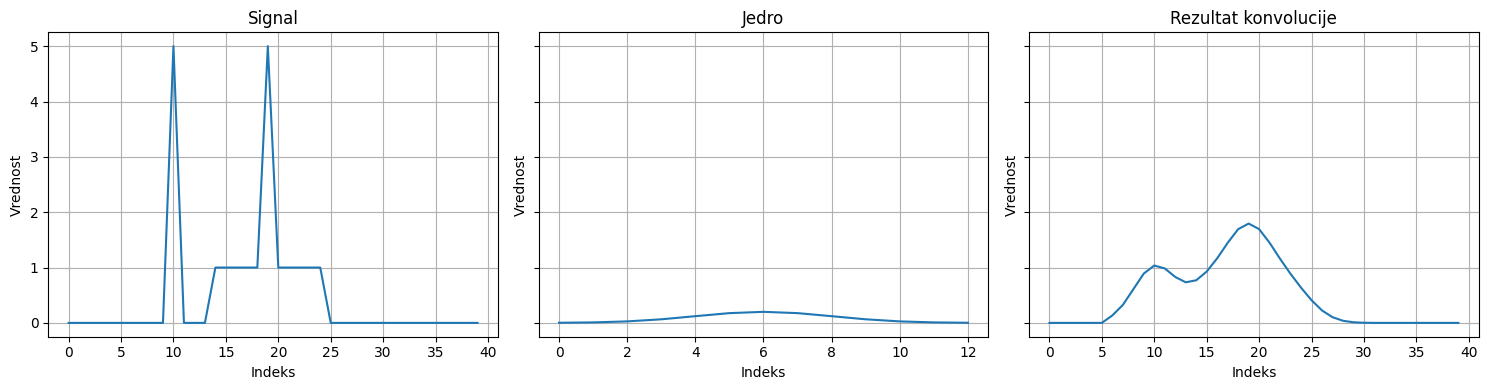

In [90]:
signal = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.0, 0.0, 
0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 5.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 
0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0])

kernel = np.array([0.0022181959, 0.0087731348, 0.027023158, 0.064825185, 
0.12110939, 0.17621312, 0.19967563, 0.17621312, 0.12110939, 0.064825185, 
0.027023158, 0.0087731348, 0.0022181959])

result = simple_convolution(signal, kernel)

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

ax[0].plot(signal)
ax[0].set_title("Signal")

ax[1].plot(kernel)
ax[1].set_title("Jedro")

ax[2].plot(result)
ax[2].set_title("Rezultat konvolucije")

for a in ax:
    a.set_xlabel("Indeks")
    a.set_ylabel("Vrednost")
    a.grid()

plt.tight_layout()
plt.show()

Jedro je v obliki Gaussove krivulje. Sestevek jedra pa je 1, ce bi bil vecji ali manjsi bi povecal/zmanjsal aplitudo koncnega rezultata.

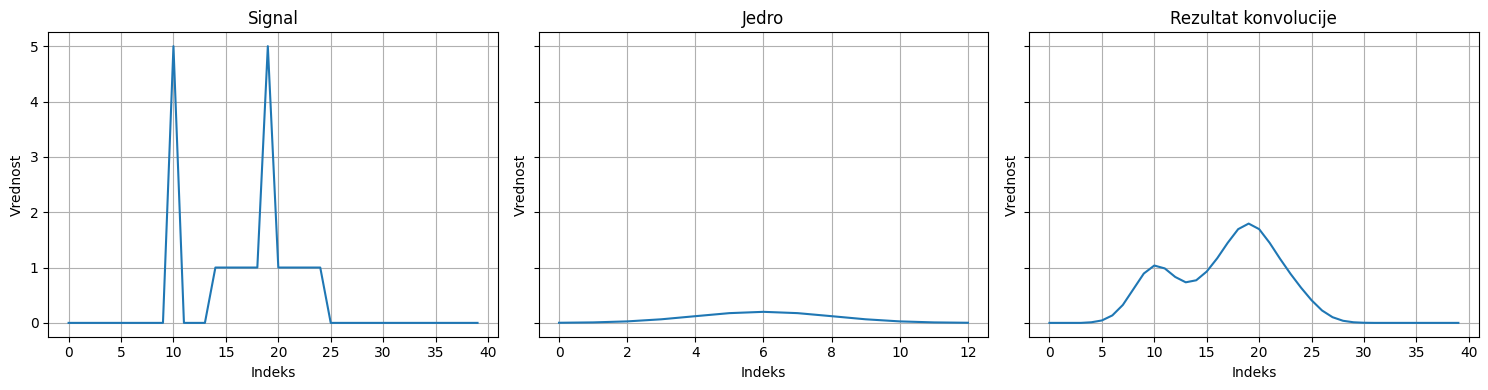

In [91]:
result = np.convolve(signal, kernel, mode='same')

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

ax[0].plot(signal)
ax[0].set_title("Signal")

ax[1].plot(kernel)
ax[1].set_title("Jedro")

ax[2].plot(result)
ax[2].set_title("Rezultat konvolucije")

for a in ax:
    a.set_xlabel("Indeks")
    a.set_ylabel("Vrednost")
    a.grid()

plt.tight_layout()
plt.show()

Flag `same` vrne rezultat, ki je v velikosti vecjega od dveh operandov. Razlike: np implemetacija racuna tudi robne 0, ki jih potem ne prikaze. Tudi obrne jedro pred operacijo, ampak pri simetricnemu jedru ni razlike.

In [92]:
def simple_gauss(sigma):
    size = 2 * math.ceil(3 * sigma) + 1
    half = size // 2
    x = np.arange(-half, half + 1)
    gauss = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * (x / sigma) ** 2)
    
    #normalisation
    gauss /= np.sum(gauss)
    return gauss

In [93]:
gauss = simple_gauss(2.0)
print(gauss)
print(np.sum(simple_gauss(2.0)))

[0.0022182  0.00877313 0.02702316 0.06482519 0.12110939 0.17621312
 0.19967563 0.17621312 0.12110939 0.06482519 0.02702316 0.00877313
 0.0022182 ]
0.9999999999999999


sigma=0.5
sestevek: 1.0000000000000002
sigma=1
sestevek: 1.0
sigma=2
sestevek: 0.9999999999999999
sigma=3
sestevek: 1.0000000000000002
sigma=4
sestevek: 1.0


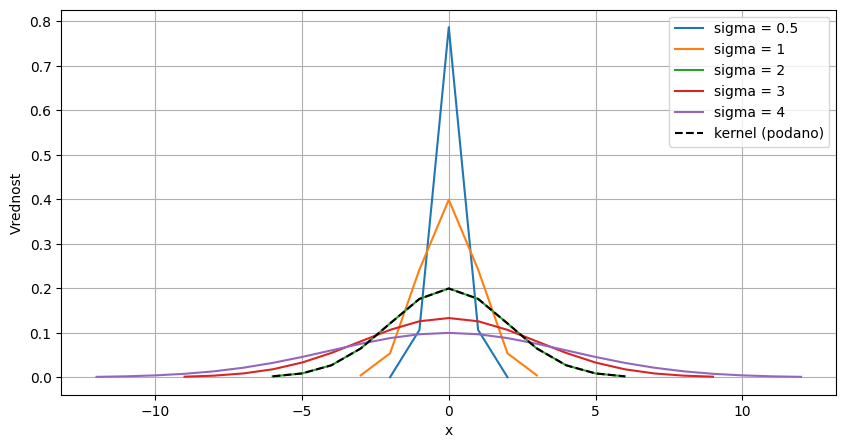

In [94]:
#e.)
sigmas = [0.5, 1, 2, 3, 4]

plt.figure(figsize=(10, 5))

for sigma in sigmas:
    g = simple_gauss(sigma)
    x = np.arange(len(g)) - len(g) // 2

    print(f'{sigma=}')
    plt.plot(x, g, label=f"sigma = {sigma}")
    print(f'sestevek: {np.sum(g)}')


x_kernel = np.arange(len(kernel)) - len(kernel) // 2
plt.plot(x_kernel, kernel, 'k--', label="kernel (podano)")

plt.xlabel("x")
plt.ylabel("Vrednost")
plt.legend()
plt.grid()
plt.show()

In [9]:
#f.)

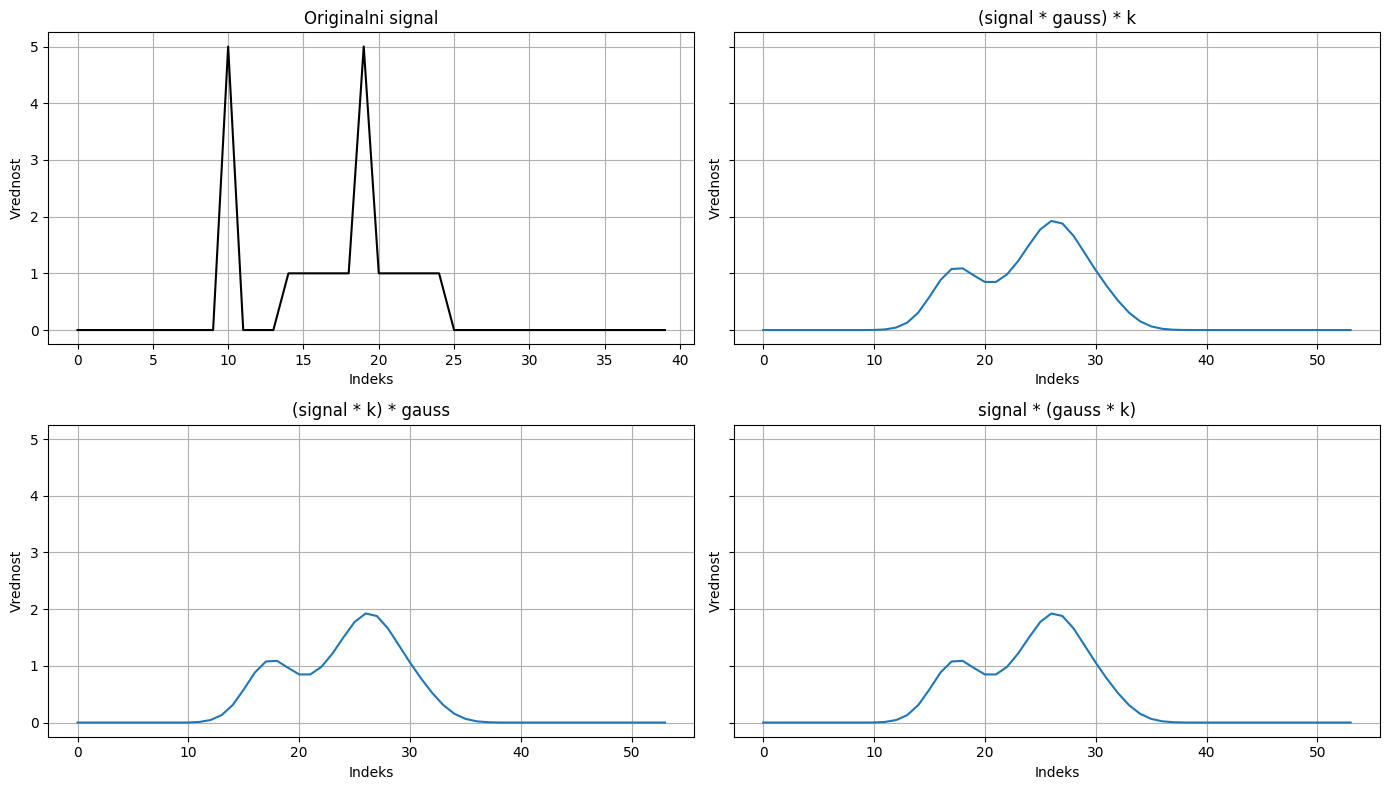

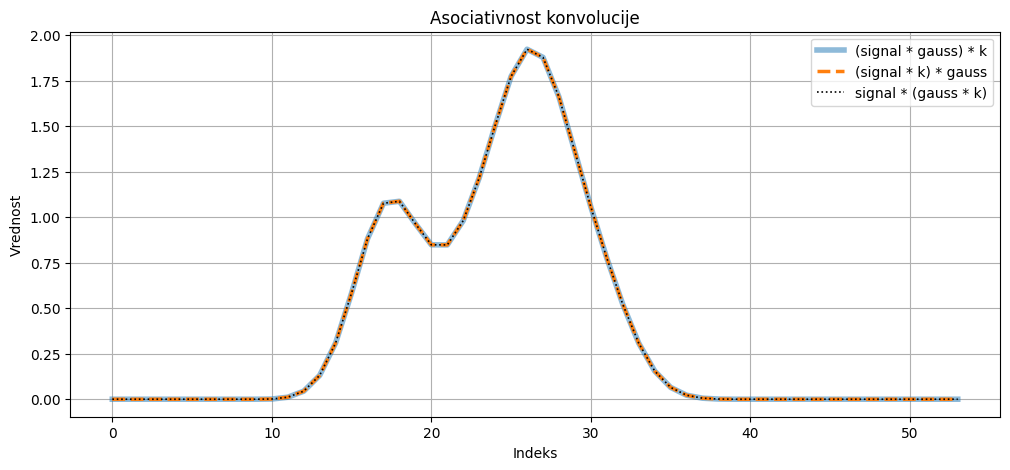

a vs b isclose: True
a vs c isclose: True


In [95]:
#g.)

k = np.array([0.1, 0.6, 0.4])

signal_gauss = np.convolve(signal, gauss, mode='full')
signal_gauss_k = np.convolve(signal_gauss, k, mode='full')

signal_k = np.convolve(signal, k, mode='full')
signal_k_gauss = np.convolve(signal_k, gauss, mode='full')

gauss_k = np.convolve(gauss, k, mode='full')
signal_both = np.convolve(signal, gauss_k, mode='full')




#vizualizacija .......
fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharey=True)

ax[0, 0].plot(signal, 'k')
ax[0, 0].set_title("Originalni signal")

ax[0, 1].plot(signal_gauss_k)
ax[0, 1].set_title("(signal * gauss) * k")

ax[1, 0].plot(signal_k_gauss)
ax[1, 0].set_title("(signal * k) * gauss")

ax[1, 1].plot(signal_both)
ax[1, 1].set_title("signal * (gauss * k)")

for a in ax.flat:
    a.set_xlabel("Indeks")
    a.set_ylabel("Vrednost")
    a.grid()

plt.tight_layout()
plt.show()

# primerjava vseh treh rezultatov na enem grafu
plt.figure(figsize=(12, 5))
plt.plot(signal_gauss_k, label="(signal * gauss) * k", linewidth=4, alpha=0.5)
plt.plot(signal_k_gauss, label="(signal * k) * gauss", linewidth=2.5, linestyle='--')
plt.plot(signal_both, label="signal * (gauss * k)", linewidth=1.2, linestyle=':', color='k')
plt.xlabel("Indeks")
plt.ylabel("Vrednost")
plt.title("Asociativnost konvolucije")
plt.legend()
plt.grid()
plt.show()

print("a vs b isclose:", np.isclose(signal_gauss_k, signal_k_gauss).all())
print("a vs c isclose:", np.isclose(signal_gauss_k, signal_both).all())


In [96]:
#h.)
def gauss_filter(sigma, image):
    g = simple_gauss(sigma)
    row = g.reshape(1, -1)
    col = g.reshape(-1, 1)

    result = cv2.filter2D(image, -1, row)
    result = cv2.filter2D(result, -1, col)
    return result


isti rezultat: True


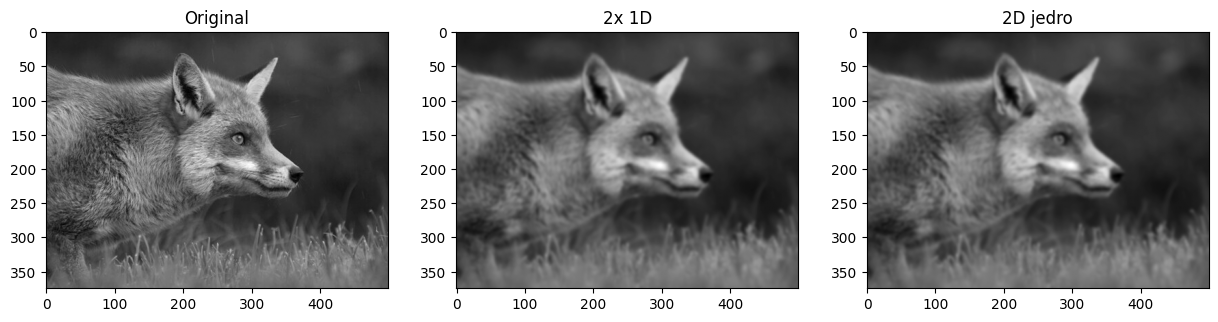

In [98]:
fox = cv2.imread('images/fox.jpg', cv2.IMREAD_GRAYSCALE)

simple = simple_gauss(2.0)
simple_row = np.expand_dims(simple, axis=0)
simple_col = simple_row.T  # Transpose to get a column

#1D
result_1d = cv2.filter2D(fox, -1, simple_row, borderType=cv2.BORDER_REPLICATE)
result_1d = cv2.filter2D(result_1d, -1, simple_col, borderType=cv2.BORDER_REPLICATE)

#2D
result_2d = simple_row.T @ simple_row  # 2D Gauss filter z mnozenjem
result_2d = cv2.filter2D(fox, -1, result_2d, borderType=cv2.BORDER_REPLICATE)


print("isti rezultat:", np.allclose(result_1d, result_2d, atol=1))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(fox, cmap='gray');    ax[0].set_title("Original")
ax[1].imshow(result_1d, cmap='gray'); ax[1].set_title("2x 1D")
ax[2].imshow(result_2d, cmap='gray'); ax[2].set_title("2D jedro")
plt.show()


In [ ]:
cameraManGauss = cv2.imread('images/cameraman_gauss.png', cv2.IMREAD_GRAYSCALE)
cameraManSaltPepper = cv2.imread('images/cameraman_sp.png', cv2.IMREAD_GRAYSCALE)

cameraManGaussFiltered = gauss_filter(2.0, cameraManGauss)
cameraManSaltPepperFiltered = gauss_filter(2.0, cameraManSaltPepper)

# vizualizacija z drsnikom za sigma
out = widgets.Output()

def update(sigma):
    gauss_filtered = gauss_filter(sigma, cameraManGauss)
    sp_filtered = gauss_filter(sigma, cameraManSaltPepper)

    with out:
        out.clear_output(wait=True)   # pocisti staro sliko, nato narisi novo
        fig, ax = plt.subplots(2, 2, figsize=(9, 9))
        ax[0, 0].imshow(cameraManGauss, cmap='gray', vmin=0, vmax=255)
        ax[0, 0].set_title("cameraman (gauss)")
        ax[0, 1].imshow(gauss_filtered, cmap='gray', vmin=0, vmax=255)
        ax[0, 1].set_title(f"po filtru (sigma = {sigma})")
        ax[1, 0].imshow(cameraManSaltPepper, cmap='gray', vmin=0, vmax=255)
        ax[1, 0].set_title("cameraman (salt & pepper)")
        ax[1, 1].imshow(sp_filtered, cmap='gray', vmin=0, vmax=255)
        ax[1, 1].set_title(f"po filtru (sigma = {sigma})")
        for a in ax.flat:
            a.axis('off')
        plt.tight_layout()
        plt.show()

slider = widgets.FloatSlider(value=2.0, min=0.5, max=8.0, step=0.5,
                             description='sigma', continuous_update=False)
slider.observe(lambda change: update(change['new']), names='value')

display(slider, out)
update(slider.value)


FloatSlider(value=2.0, continuous_update=False, description='sigma', max=8.0, min=0.5, step=0.5)

Output()

: 

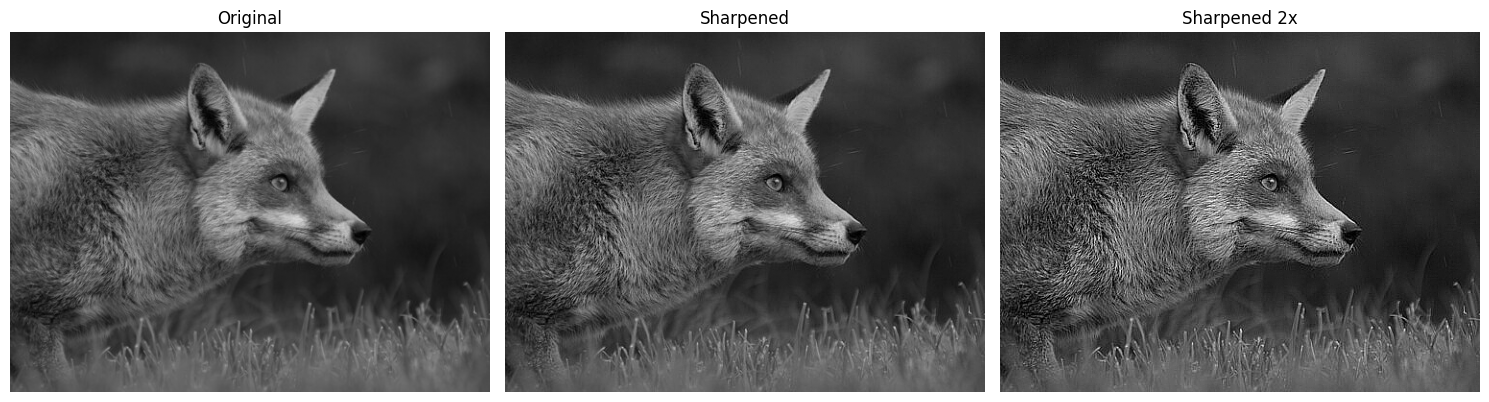

In [14]:
#i.)

sharpen = np.array([[0, 0, 0],
                    [0, 2, 0],
                    [0, 0, 0]]) - np.ones((3, 3)) / 9

filtered_image = cv2.filter2D(fox, -1, sharpen, borderType=cv2.BORDER_REPLICATE)
filtered_image2 = cv2.filter2D(filtered_image, -1, sharpen, borderType=cv2.BORDER_REPLICATE)


fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(fox, cmap='gray', vmin=0, vmax=255);             ax[0].set_title("Original")
ax[1].imshow(filtered_image, cmap='gray', vmin=0, vmax=255);  ax[1].set_title("Sharpened")
ax[2].imshow(filtered_image2, cmap='gray', vmin=0, vmax=255); ax[2].set_title("Sharpened 2x")
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()


In [15]:
#j.)

def median_filter (signal, window):
    working_signal = np.pad(signal, (window//2, window//2), mode='edge')
    result = np.zeros(signal.size)
    
    for i in range(signal.size):
        working_window = working_signal[i:i+window]
        sorted_window = np.sort(working_window)
        if working_window.size % 2 == 1:
            median = sorted_window[working_window.size // 2]    
        else:
            median = (sorted_window[working_window.size // 2 - 1] + sorted_window[working_window.size // 2]) / 2
            
        
        result[i] = median
        
    return result

In [16]:
x = np.concatenate((np.zeros(14), np.ones(11), np.zeros(15)))
 # pokvarjen signal
xc = np.copy(x)
xc[11] = 5
xc[18] = 5


guass_filtered = np.convolve(xc, simple_gauss(2.0), mode='same')
median_filtered = median_filter(xc, 3)

# vizualizacija z drsnikoma za sigma in okno
out_1d = widgets.Output()

def update_1d(sigma, window):
    guass_filtered = np.convolve(xc, simple_gauss(sigma), mode='same')
    median_filtered = median_filter(xc, window)

    with out_1d:
        out_1d.clear_output(wait=True)
        fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

        ax[0].plot(xc)
        ax[0].set_title("Pokvarjen signal")

        ax[1].plot(guass_filtered)
        ax[1].set_title(f"Gaussov filter (sigma = {sigma})")

        ax[2].plot(median_filtered)
        ax[2].set_title(f"Medianin filter (okno {window})")

        for a in ax:
            a.plot(x, 'k--', alpha=0.4, label="izvirna stopnica")
            a.set_xlabel("Indeks")
            a.set_ylabel("Vrednost")
            a.grid()
        ax[0].legend()

        plt.tight_layout()
        plt.show()

sigma_slider = widgets.FloatSlider(value=2.0, min=0.5, max=8.0, step=0.5,
                                   description='sigma', continuous_update=False)
window_slider = widgets.IntSlider(value=3, min=1, max=15, step=2,   # samo liha okna
                                  description='okno', continuous_update=False)

def on_change(change):
    update_1d(sigma_slider.value, window_slider.value)

sigma_slider.observe(on_change, names='value')
window_slider.observe(on_change, names='value')

display(sigma_slider, window_slider, out_1d)
update_1d(sigma_slider.value, window_slider.value)


FloatSlider(value=2.0, continuous_update=False, description='sigma', max=8.0, min=0.5, step=0.5)

IntSlider(value=3, continuous_update=False, description='okno', max=15, min=1, step=2)

Output()

In [17]:
#k.)

def median_filter_2d(image, window):
    pad_size = window // 2
    padded_image = np.pad(image, pad_size, mode='edge')
    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            working_window = padded_image[i:i+window, j:j+window]
            median = np.median(working_window)
            result[i, j] = median

    return result

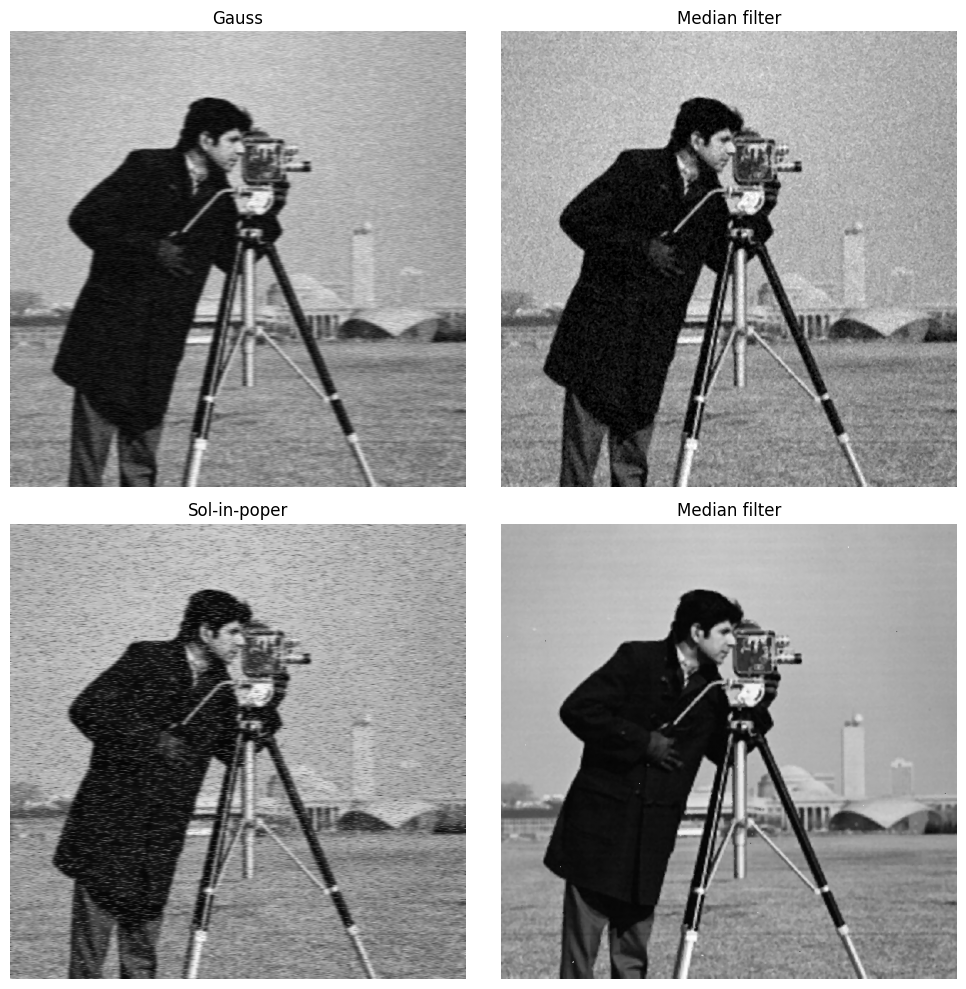

In [18]:
median_guauss_filtered = median_filter_2d(cameraManGauss, 3)
median_salt_pepper_filtered = median_filter_2d(cameraManSaltPepper, 3)

# vizualizacija
fig, ax = plt.subplots(2, 2, figsize=(10, 10))

ax[0, 0].imshow(gauss_filter(2.0, cameraManGauss), cmap='gray', vmin=0, vmax=255)
ax[0, 0].set_title("Gauss")

ax[0, 1].imshow(median_guauss_filtered, cmap='gray', vmin=0, vmax=255)
ax[0, 1].set_title("Median filter")

ax[1, 0].imshow(gauss_filter(2.0, cameraManSaltPepper), cmap='gray', vmin=0, vmax=255)
ax[1, 0].set_title("Sol-in-poper")

ax[1, 1].imshow(median_salt_pepper_filtered, cmap='gray', vmin=0, vmax=255)
ax[1, 1].set_title("Median filter")

for a in ax.flat:
    a.axis('off')
plt.tight_layout()
plt.show()


N = image size
w = window size

Casovna kompleksnost mojega filtra je $O(N^2 * w^2 * log (w))$

Casovna kompleksnost Gaussovega filtra je $O(N^2 * w^2)$





### 2. Odvodi slik

In [19]:
#a.)
def simple_gaussdx(sigma):
    half = math.ceil(3 * sigma)
    x = np.arange(-half, half + 1)
    
    d = -1 / (sigma**3 * np.sqrt(2 * np.pi)) * x * np.exp(-x**2 / (2 * sigma**2))

    
    normalised = d/(0.5 * np.sum(np.abs(d)))
    
    return normalised


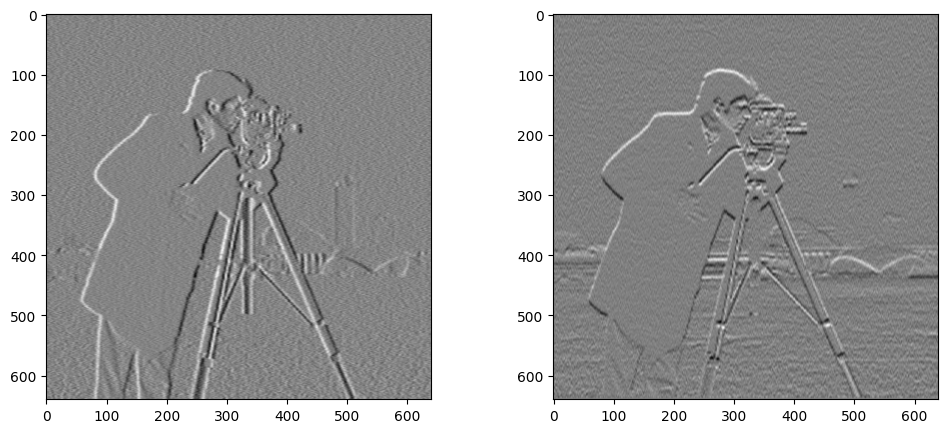

In [20]:
d = simple_gaussdx(2.0)
dx = np.expand_dims(d, axis=0)  #Concert to 2D
dy = dx.T  # Dobit vrstice (transponirano)

cameraManGauss64 = cameraManGauss.astype(np.float64)

Ix = cv2.filter2D(cameraManGauss64, -1, dx)
Iy = cv2.filter2D(cameraManGauss64, -1, dy)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(Ix, cmap='gray')
ax[1].imshow(Iy, cmap='gray')



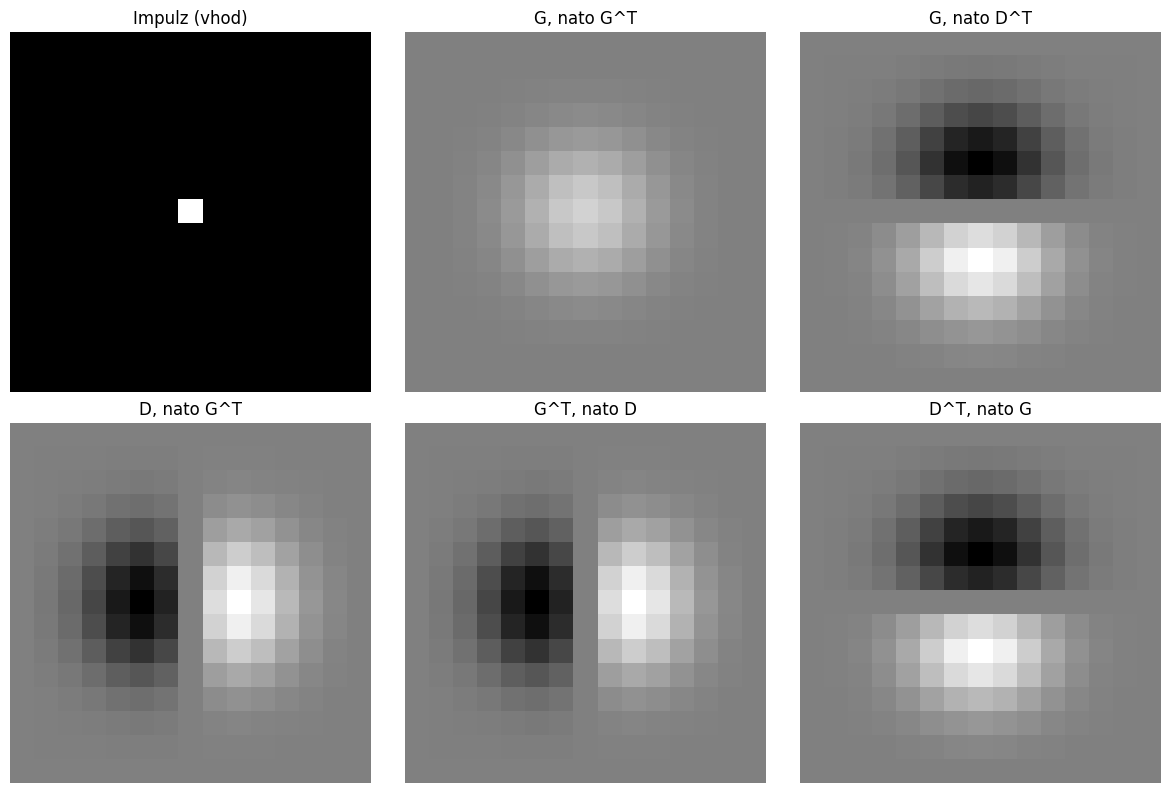

G, D^T  == D^T, G : True
D, G^T  == G^T, D : True


In [21]:
#b.)

I = np.zeros((15, 15), dtype=np.float64)
I [7,7] = 1.0

G = np.expand_dims(simple_gauss(2.0), axis=0)
D = np.expand_dims(simple_gaussdx(2.0), axis=0)

def apply(img, k1, k2):
    return cv2.filter2D(cv2.filter2D(img, -1, k1), -1, k2)


GGT = (apply(I, G, G.T))
GDT = (apply(I, G, D.T))
DGT = (apply(I, D, G.T))
GTD = (apply(I, G.T, D))
DTG = (apply(I, D.T, G))

# vizualizacija impulznih odzivov (2 vrstici)
results = [("G, nato G^T", GGT), ("G, nato D^T", GDT), ("D, nato G^T", DGT),
           ("G^T, nato D", GTD), ("D^T, nato G", DTG)]
m = max(np.abs(r).max() for _, r in results)   # skupno simetricno obmocje okoli 0

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax[0, 0].imshow(I, cmap='gray')
ax[0, 0].set_title("Impulz (vhod)")
for a, (title, r) in zip(ax.flat[1:], results):
    a.imshow(r, cmap='gray', vmin=-m, vmax=m)
    a.set_title(title)
for a in ax.flat:
    a.axis('off')
plt.tight_layout()
plt.show()

# ali je vrstni red pomemben?
print("G, D^T  == D^T, G :", np.allclose(GDT, DTG))
print("D, G^T  == G^T, D :", np.allclose(DGT, GTD))


### 3. Detekcija robov

In [22]:
#a.)

def gradient_magnitude(image):
    
    image = image.astype(np.float64)
    
    d = np.expand_dims(simple_gaussdx(1.0), axis=0)
    Ix = cv2.filter2D(image, -1, d)
    Iy = cv2.filter2D(image, -1, d.T)

    
    magnitude = np.sqrt(Ix**2 + Iy**2)
    angle = np.arctan2(Iy, Ix)
    
    return magnitude, angle, Ix, Iy

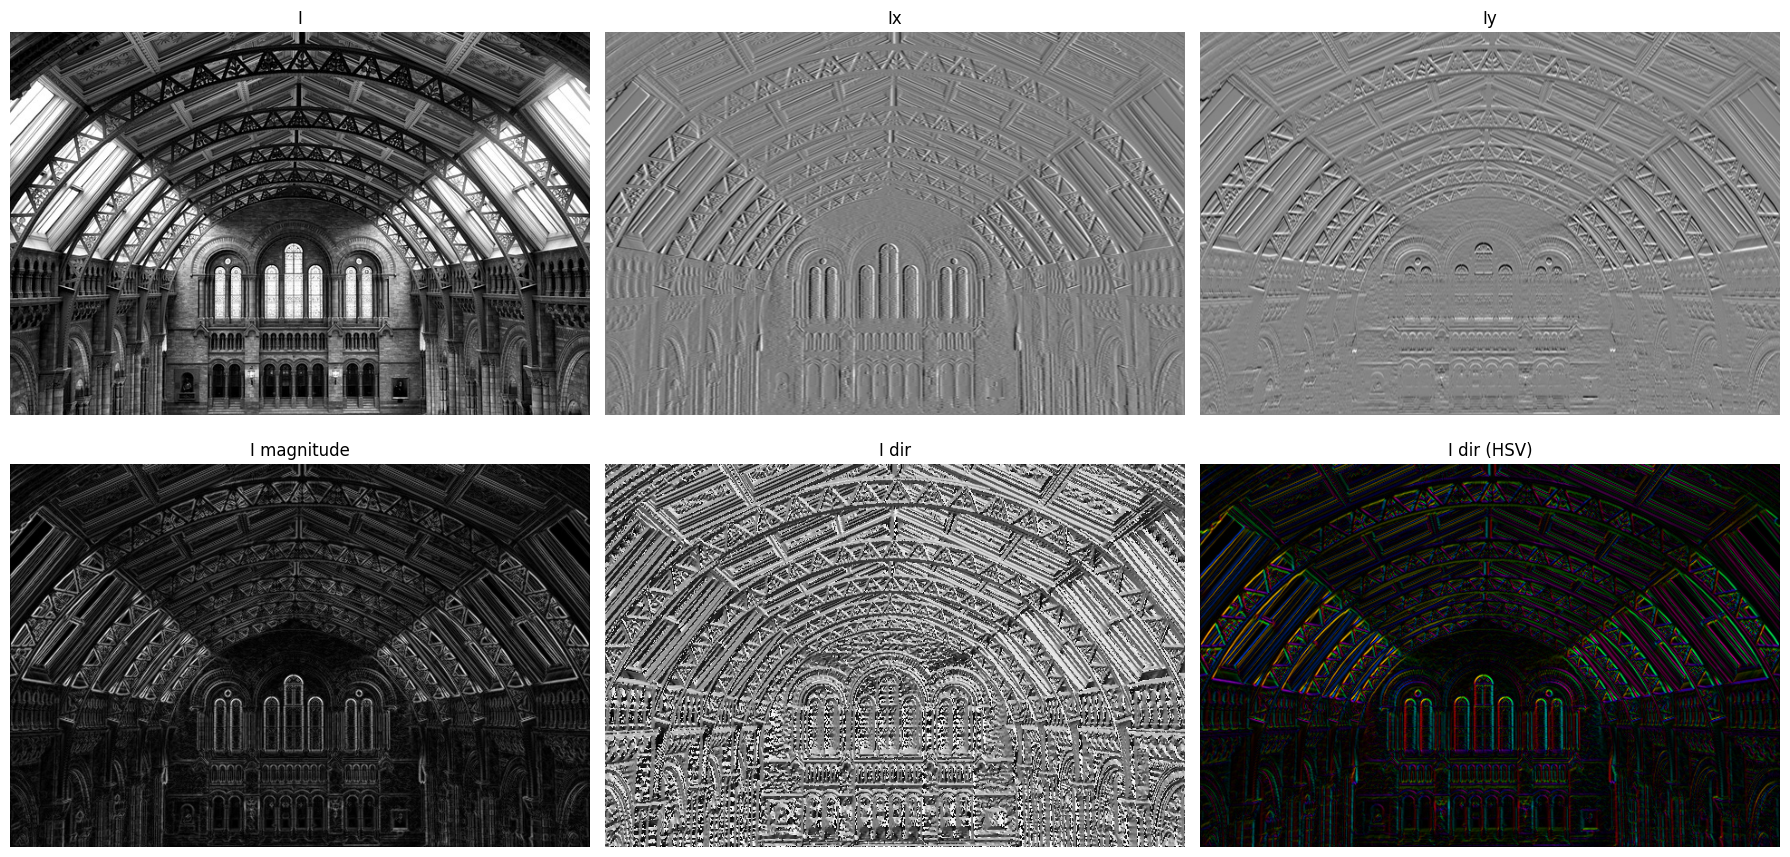

In [23]:
museum = cv2.imread('images/museum.jpg', cv2.IMREAD_GRAYSCALE)
magnitude, angle, Ix, Iy = gradient_magnitude(museum)


H = (angle + np.pi) / (2 * np.pi) * 360
V = magnitude / magnitude.max()
hsv = np.dstack((H, np.ones_like(H), V)).astype(np.float32)
rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
ax[0, 0].imshow(museum, cmap='gray');    ax[0, 0].set_title("I")
ax[0, 1].imshow(Ix, cmap='gray');        ax[0, 1].set_title("Ix")
ax[0, 2].imshow(Iy, cmap='gray');        ax[0, 2].set_title("Iy")
ax[1, 0].imshow(magnitude, cmap='gray'); ax[1, 0].set_title("I magnitude")
ax[1, 1].imshow(angle, cmap='gray');     ax[1, 1].set_title("I dir")
ax[1, 2].imshow(rgb);                    ax[1, 2].set_title("I dir (HSV)")
for a in ax.flat:
    a.axis('off')
plt.tight_layout()
plt.show()


In [24]:
#b.)

def simple_edges(image, threshold):
    magnitude, angle, Ix, Iy = gradient_magnitude(image)
    
    edges = np.zeros_like(magnitude, dtype=np.uint8)
    edges[magnitude > threshold] = 255
    
    return edges

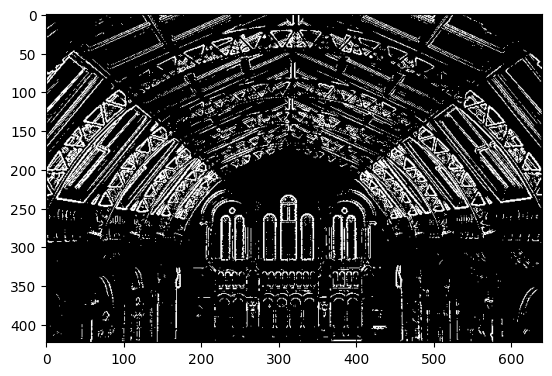

In [25]:
edge_detected = simple_edges(museum, 80)

plt.imshow(edge_detected, cmap='gray')

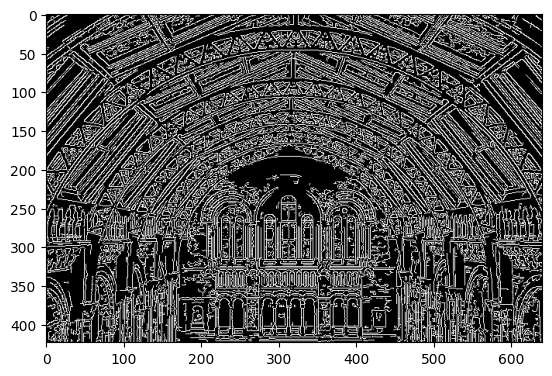

In [ ]:
#c.)

canny_edges = cv2.Canny(museum, 100, 200) #image, threshold1, threshold2, aperatureSize, L2gradient
plt.imshow(canny_edges, cmap='gray')

In [4]:
cap = cv2.VideoCapture(0)
for _ in range(10):
    _, frame = cap.read()
cap.release()

photo = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)


out_canny = widgets.Output()

def update_canny(low, high):
    edges = cv2.Canny(photo, low, high)
    with out_canny:
        out_canny.clear_output(wait=True)
        fig, ax = plt.subplots(1, 2, figsize=(14, 6))
        ax[0].imshow(photo, cmap='gray')
        ax[0].set_title("Slika s kamere")
        ax[1].imshow(edges, cmap='gray')
        ax[1].set_title(f"Canny (threshold1 = {low}, threshold2 = {high})")
        for a in ax:
            a.axis('off')
        plt.tight_layout()
        plt.show()

low_slider = widgets.IntSlider(value=100, min=0, max=500, step=10,
                               description='threshold1', continuous_update=False)
high_slider = widgets.IntSlider(value=200, min=0, max=500, step=10,
                                description='threshold2', continuous_update=False)

def on_change_canny(change):
    update_canny(low_slider.value, high_slider.value)

low_slider.observe(on_change_canny, names='value')
high_slider.observe(on_change_canny, names='value')

display(low_slider, high_slider, out_canny)
update_canny(low_slider.value, high_slider.value)


IntSlider(value=100, continuous_update=False, description='threshold1', max=500, step=10)

IntSlider(value=200, continuous_update=False, description='threshold2', max=500, step=10)

Output()

In [ ]:
cap = cv2.VideoCapture(0)

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        gray = np.float32(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))

        harris = cv2.cornerHarris(gray, 7, 3, 0.04) #src, blockSize, ksize, k, borderType
        harris = cv2.dilate(harris, None)

        frame[harris > 0.01 * harris.max()] = [0, 0, 255]

        cv2.imshow("Koti", frame)

        key = cv2.waitKey(1) & 0xFF
        if key == ord('q'):
            break
        
except KeyboardInterrupt:
    pass

finally:
    cap.release()
    cv2.destroyAllWindows()
    for _ in range(5):
        cv2.waitKey(1)


### 4. Detekcija crt in robov

$$ A = (0, 0); B = (1, 1); C = (1, 0); D = (2, 2) $$
A:
$$ \rho_A = 0 \cos (\theta) + 0 \sin (\theta) $$
$$ \rho_A = 0 $$

B:
$$ \rho_B = 1 \cos (\theta) + 1 \sin (\theta) $$
$$ \rho_B = \cos (\theta) + \sin (\theta) $$

C:
$$ \rho_C = 1 \cos (\theta) + 0 \sin (\theta) $$
$$ \rho_C = \cos (\theta) $$

D:
$$ \rho_D = 2 \cos (\theta) + 2 \sin (\theta) $$

---

A = B

$$ 0 = \cos (\theta) + \sin (\theta) $$
$$ -\cos (\theta) = \sin (\theta) $$
$$ - \frac {\cos(\theta)}{\cos(\theta)} = \frac {\sin(\theta)}{\cos(\theta)} $$
$$ -1 = \tan(\theta) $$
$$ \theta = \arctan(-1) $$
$$ \theta = 135^\circ $$

---

B:

$$ \rho_B = \cos (\theta) + \sin (\theta) $$
$$ \rho_B = \cos (135) + \sin (135) $$
$$ \rho_B = -\frac {\sqrt{2}}{2} + \frac {\sqrt{2}}{2} $$
$$ \rho_B = 0 $$
<br></br>
$$ \rho_B = x * \cos (\theta) + y * \sin (\theta) $$
$$ 0 = x * \cos (135) + y * \sin(135) $$
$$ 0 = x(-\frac {\sqrt{2}}{2}) + y(\frac {\sqrt{2}}{2}) $$
$$ 0 = -x + y $$
$$ x = y $$

---

A = C:

$$ 0 = \cos (\theta) $$
$$ \theta = \arccos(0) $$
$$ \theta = 90 $$
<br></br>
$$ \rho_C = cos(90) $$
$$ \rho_C = 0 $$

---
C:

$$ \rho_C = x * \cos (\theta) + y * \sin (\theta) $$
$$ 0 = x(\cos(90)) + y (\sin(90))$$
$$ 0 = 0 + y $$
$$ y = 0 $$

---

B = C:


$$ \rho_C = \rho_B $$
$$ \cos(\theta) + \sin(\theta) = \cos(\theta) $$
$$ \sin(\theta) = 0 $$
$$ \theta = \arcsin(0) $$
$$ \theta = 0 $$

---

C: 

$$ \rho_C = \cos(0) $$
$$ \rho_C = 1 $$

---

B = C

$$ \rho = x(\cos(\theta)) + y(\sin(\theta)) $$
$$ 1 = x(\cos(0)) + y(\sin(0)) $$
$$ 1 = x $$
$$ x = 1 $$

---

C = D

$$ \rho_C = \rho_D $$
$$ \cos(\theta) = 2 \cos (\theta) + 2 \sin (\theta) $$
$$ 0 = \cos(\theta) + 2 \sin(\theta) $$
$$ -\cos(\theta) = 2 \sin(\theta) $$
$$ - \frac{\cos(\theta)}{\cos(\theta)} = \frac{2\sin(\theta)}{\cos(\theta)} $$
$$ -1 = 2\tan(\theta) $$
$$  \tan(\theta) = -\frac{1}{2} $$
$$ \theta = \arctan(-\frac{1}{2}) $$
$$ \theta = 153.435 $$

---
D:

$$ \rho_D = \cos(153.435) $$
$$ \rho_D = -0.894 $$

---

C = D

$$ \rho_D = x \cos (\theta) + y \sin (\theta) $$
$$ -0.894 = x \cos(153.435) + y \sin (153.435) $$
$$ -0.894 = x * -0.894 + y * 0.447 $$
$$ -0.894 = x * -0.894 + y * 0.447 $$
$$ 1 = x + -\frac{y * 0.447}{0.894} $$
$$ 1 - x = -\frac{y * 0.447}{0.894} $$
$$ x- 1 = \frac{y * 0.447}{0.894} $$
$$ 0.894 (x-1) = 0.447y $$
$$ \frac{0.894}{0.447} (x-1) = y $$
$$ 2(x-1) = y $$
$$ y = 2x -2 $$

---

A, B, D: y = x <br>
A, C: y = 0<br>
B, C: x = 1<br>
C, D: y = 2x - 2




b.)

A = (10, 1)<br>
B = (11, 0)


$$ \rho_A = 10 \cos(\theta) + \sin(\theta) $$
$$ \rho_B = 11 \cos(\theta) + 0 \sin(\theta) $$
$$ \rho_B = 11 \cos(\theta)$$

A = B

$$ 10 \cos(\theta) + \sin(\theta) = 11\cos(\theta) $$
$$ \sin(\theta) = \cos(\theta) $$
$$ \tan(\theta) = 1 $$
$$ \theta = \arctan (1) $$
$$ \theta = 45 $$

B:

$$ \rho_B = 11 \cos(\theta) $$
$$ \rho_B = 11 \cos(45) $$
$$ \rho_B = 11 \frac{\sqrt{2}}{2} $$
$$ \rho_B = 7.778 $$

B:

$$ \rho_B = x \cos(\theta) + y \sin(\theta) $$
$$ 7.778 = x \cos(45) + y \sin(45)$$
$$ 7.778 = x \frac{\sqrt{2}}{2} + y \frac{\sqrt{2}}{2} $$
$$ \frac{2*7.778}{\sqrt2} = x + y $$
$$ \frac{15.556}{\sqrt2} = x + y $$
$$ y = - x +\frac{15.556}{\sqrt2} $$
$$ y = -x + 11 $$




In [35]:
#c.)
from utils import draw_line

def houghTranform(edges, n_theta, n_rho):
    heigth, width = edges.shape
    
    diagonal = np.sqrt(heigth**2 + width ** 2)
    
    thetas = np.linspace(-np.pi/2, np.pi/2, n_theta, endpoint = False)
    
    rhos = np.linspace(-diagonal, diagonal, n_rho)
    
    #prazna matrika
    
    accumulator = np.zeros((n_theta, n_rho), dtype=np.int32)
    
    #koordinate vseh tock na robovih
    
    ys, xs = np.nonzero(edges)
    
    for x, y in zip(xs, ys):
        for theta_idx, theta in enumerate(thetas):
            
            #enacba polarne premice
            rho = x * np.cos(theta) + y * np.sin(theta)
            
            rho_idx = int(np.round(
                (rho + diagonal) / (2 * diagonal) * (n_rho - 1)
            ))
            
            rho_idx = np.clip(rho_idx, 0, n_rho - 1)
            
            #glas za celico
            
            accumulator[theta_idx, rho_idx] += 1
            
    return accumulator, thetas, rhos
    
    

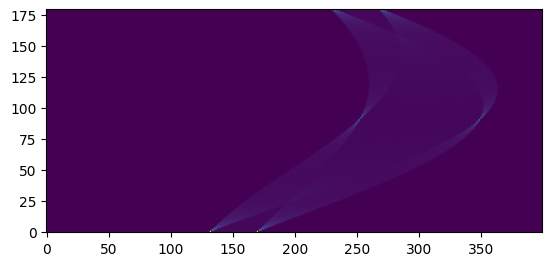

In [36]:
img = cv2.imread("images/rectangle.png", cv2.IMREAD_GRAYSCALE)

edges = cv2.Canny(img, 50, 150)

accumulator, thetas, rhos = houghTranform(edges, 180, 400)

plt.imshow(accumulator, origin="lower")

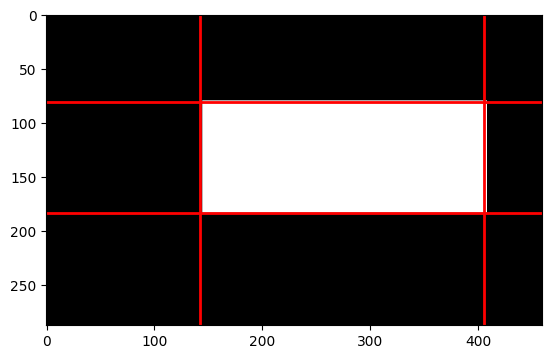

In [47]:

threshold = 0.25 * accumulator.max()

acc = accumulator.copy()
acc[acc < threshold] = 0

h, w = img.shape

plt.figure()
plt.imshow(img, cmap="gray")

for i in range(4):

    maximum = np.max(acc)


    # find max
    theta_idx, rho_idx = np.where(acc == maximum)
    theta_idx = theta_idx[0]
    rho_idx = rho_idx[0]

    # draw line
    theta = thetas[theta_idx]
    rho = rhos[rho_idx]

    draw_line(rho, theta, h, w, clr="r", linewidth=2)

    # Nearby cells set to 0
    acc[
        max(0, theta_idx-5):theta_idx+6,
        max(0, rho_idx-8):rho_idx+9
    ] = 0

    # Preverimo ce se crta nahajajo na zacetku ali na koncu akumulatorkse matrike
    # Ce se nahaja na koncu obstaja se en zapis iste daljica zato izracunamo
    # nasportni rho in nastavimo okrog njega na 0
    if theta_idx < 5 or theta_idx >= len(thetas)-5:
        opposite_rho = len(rhos) - 1 - rho_idx
        
        #zadnjih 5 daljic
        theta_start = len(thetas)-5
        theta_end = len(thetas)
        
        #Okrog rho
        rho_start = max(0, opposite_rho - 8)
        rho_end = min(len(rhos), opposite_rho + 9)

        #nvse med tem v akumulator funkciji na 0
        acc[theta_start:theta_end, rho_start:rho_end] = 0

plt.show()


In [69]:
def nonmaxima_suppression_box(A, w):
    result = np.zeros_like(A)
    
    half = w//2
    
    rows, cols = np.nonzero(A)
    
    for row, col in zip(rows, cols):
        
        
        row_start = max(0, row - half)
        row_end = min(A.shape[0], row + half + 1)
        
        col_start = max(0, col - half)
        col_end = min(A.shape[1], col + half + 1)
        
        window = A[row_start:row_end, col_start:col_end]
        
        
        if A[row,col] == np.max(window):
            result[row, col] = A[row, col]
            
    return result

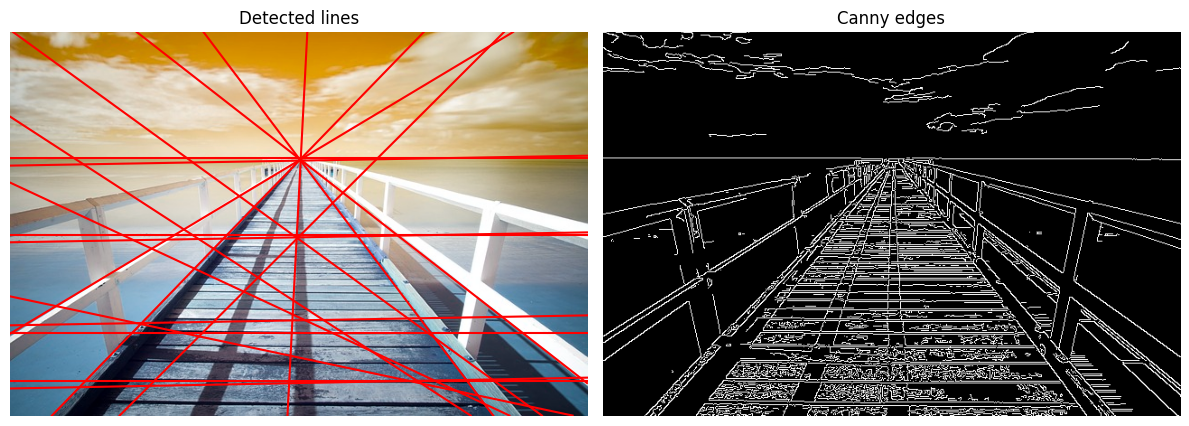

In [70]:
img = cv2.imread("images/pier.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150)

accumulator, thetas, rhos = houghTranform(edges, 180, 400)
threshold = 0.4 * accumulator.max()

acc = accumulator.copy()
acc[acc<threshold] = 0

acc_nms = nonmaxima_suppression_box(acc, 21)

theta_idxs, rho_idxs = np.nonzero(acc_nms)

#get votes
votes = acc_nms[theta_idxs, rho_idxs]

#sort votes
indices = np.argsort(votes)[::-1][:30]

h, w = img.shape[:2]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original image with detected lines
axes[0].imshow(img, cmap="gray")
plt.sca(axes[0])

for i in indices:
    theta = thetas[theta_idxs[i]]
    rho = rhos[rho_idxs[i]]
    draw_line(rho, theta, h, w, clr="r", linewidth=1.5)

axes[0].set_title("Detected lines")
axes[0].axis("off")

# Canny edges
axes[1].imshow(edges, cmap="gray")
axes[1].set_title("Canny edges")
axes[1].axis("off")

plt.tight_layout()
plt.show()

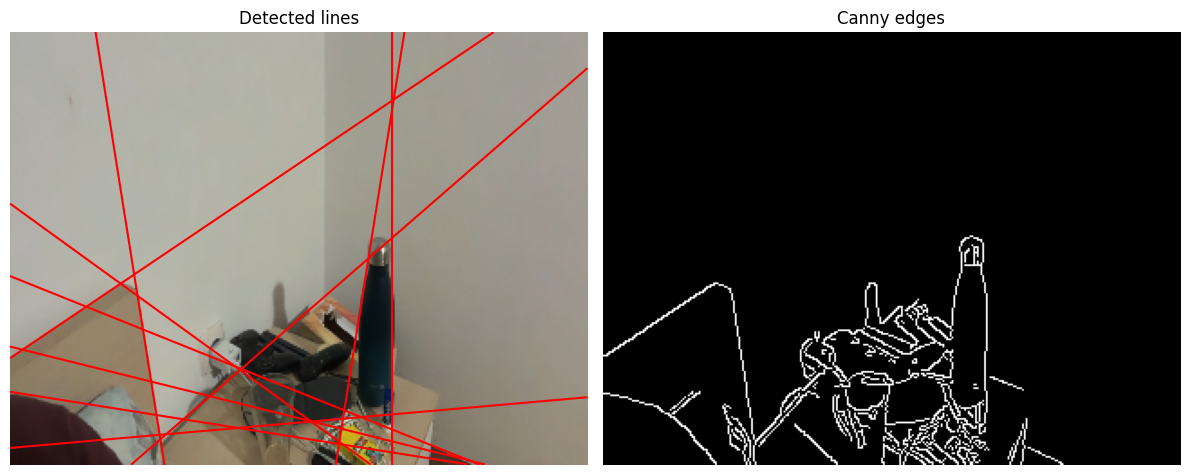

In [82]:
cap = cv2.VideoCapture(0)
for _ in range(10):
    _, frame = cap.read()
cap.release()

img = cv2.resize(frame, (320, 240))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 80, 160)

accumulator, thetas, rhos = houghTranform(edges, 180, 400)
threshold = 0.4 * accumulator.max()

acc = accumulator.copy()
acc[acc<threshold] = 0

acc_nms = nonmaxima_suppression_box(acc, 11)

theta_idxs, rho_idxs = np.nonzero(acc_nms)

#get votes
votes = acc_nms[theta_idxs, rho_idxs]

#sort votes
indices = np.argsort(votes)[::-1][:10]

h, w = img.shape[:2]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Camera image with detected lines
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.sca(axes[0])

for i in indices:
    theta = thetas[theta_idxs[i]]
    rho = rhos[rho_idxs[i]]
    draw_line(rho, theta, h, w, clr="r", linewidth=1.5)

axes[0].set_title("Detected lines")
axes[0].axis("off")

# Canny edges
axes[1].imshow(edges, cmap="gray")
axes[1].set_title("Canny edges")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### 5. Detekcija krogov

a.)
$$ r^2 = (x_0 - x_C)^2 + (y_0 - y_C)^2 $$

b.)

$$ A = (4, 8) $$
$$ B = (8, 4) $$
$$ r = 4 $$

---

A:
$$ (x_C - x_0)^2 + (y_C - y_0)^2 = r^2 $$
$$ (x_C - 4)^2 + (y_C - 8)^2 = 16 $$

B:
$$ (x_C - x_0)^2 + (y_C - y_0)^2 = r^2 $$
$$ (x_C - 8)^2 + (y_C - 4)^2 = 16 $$

A = B:
$$ (x_C - 4)^2 + (y_C - 8)^2 = (x_C - 8)^2 + (y_C - 4)^2 $$

$$ x_C^2 - 8x_C + 16 + y_C^2 - 16y_C + 64 = x_C^2 - 16x_C + 64 + y_C^2 - 8y_C + 16 $$

$$ -8x_C - 16y_C = -16x_C - 8y_C $$
$$ 8x_C - 8y_C = 0 $$
$$ x_C = y_C $$

---

$$ (x_C - 4)^2 + (x_C - 8)^2 = 16 $$
$$ x_C^2 - 8x_C + 16 + x_C^2 - 16x_C + 64 = 16 $$
$$ 2x_C^2 - 24x_C + 64 = 0 $$
$$ x_C^2 - 12x_C + 32 = 0 $$
$$ (x_C - 4)(x_C - 8) = 0 $$
$$ x_C = 4; x_C = 8 $$
$$ x_C = y_C $$

$$C_1 = (4,4) $$
$$C_2 = (8,8) $$

Obstajata 2 kroznici, ki sekata te 2 tocki.

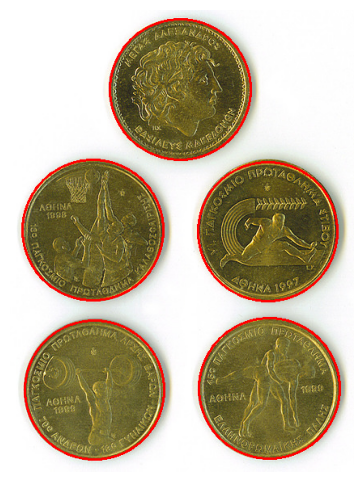

In [85]:
#.c)
img = cv2.imread("images/coins.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = cv2.medianBlur(gray, 5)


circles = cv2.HoughCircles(
    gray,
    cv2.HOUGH_GRADIENT,
    dp=1,
    minDist=150,
    param1=100,
    param2=30,
    minRadius=85,
    maxRadius=90
)

result = img.copy()

circles = np.round(circles[0]).astype(int)

for x, y, r in circles:
    cv2.circle(result, (x, y), r, (0, 0, 255), 2)


plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


In [88]:

cap = cv2.VideoCapture(1)

while True:
    ret, frame = cap.read()

    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 5)

    circles = cv2.HoughCircles(
        gray,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=60,
        param1=100,
        param2=30,
        minRadius=15,
        maxRadius=150
    )

    if circles is not None:
        circles = np.round(circles[0]).astype(int)

        for x, y, r in circles:
            cv2.circle(frame, (x, y), r, (0, 0, 255), 2)


    cv2.imshow("Circle Detection - Webcam", frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()
